# Часть 1. Проверка гипотезы в Python и составление аналитической записки

Вы предобработали данные в SQL, и теперь они готовы для проверки гипотезы в Python. Загрузите данные пользователей из Москвы и Санкт-Петербурга c суммой часов их активности из файла yandex_knigi_data.csv. Если работаете локально, скачать файл можно по ссылке.

Проверьте наличие дубликатов в идентификаторах пользователей. Сравните размеры групп, их статистики и распределение.

Напомним, как выглядит гипотеза: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

Нулевая гипотеза $H_0: \mu_{\text{СПб}} \leq \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.

Альтернативная гипотеза $H_1: \mu_{\text{СПб}} > \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

По результатам анализа данных подготовьте аналитическую записку, в которой опишите:

Выбранный тип t-теста и уровень статистической значимости.

Результат теста, или p-value.

Вывод на основе полученного p-value, то есть интерпретацию результатов.

Одну или две возможные причины, объясняющие полученные результаты.

## Напишите заголовок первой части проекта здесь

- Автор: Артемьев Константин
- Дата: 22.03.2026

## Цели и задачи проекта

<font color='#777778'>Статистически доказать, используя одностороннюю проверку гипотезы с двумя выборками:
Нулевая гипотеза 
Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.
Альтернативная гипотеза 
Среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо..</font>

## Описание данных

<font color='#777778'>Данные
https://code.s3.yandex.net/datasets/ab_test_participants.csv — таблица участников тестов.
Структура файла:
user_id — идентификатор пользователя;
group — группа пользователя;
ab_test — название теста;
device — устройство, с которого происходила регистрация.
https://code.s3.yandex.net/datasets/ab_test_events.zip — архив с одним csv-файлом, в котором собраны события 2020 года;
Структура файла:
user_id — идентификатор пользователя;
event_dt — дата и время события;
event_name — тип события;
details — дополнительные данные о событии..</font>

## Содержимое проекта

<font color='#777778'>Перечислите основные шаги проекта или напишите оглавление. Используйте описание проекта, чтобы зафиксировать основные шаги.</font>

---

## 1. Загрузка данных и знакомство с ними

Загрузите данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла `/datasets/yandex_knigi_data.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
df = pd.read_csv('/datasets/yandex_knigi_data.csv', index_col=0)
df.head()

,city,puid,hours
0,Москва,9668,26.167776
1,Москва,16598,82.111217
2,Москва,80401,4.656906
3,Москва,140205,1.840556
4,Москва,248755,151.326434


## 2. Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

In [3]:
# Явные дубликаты
print("Явные дубликаты:", df.duplicated().sum())

# Неявные дубликаты по puid
dups_puid = df['puid'].duplicated().sum()
print("Неявные дубликаты (одинаковый puid):", dups_puid)

if dups_puid > 0:
    # Посмотрим пример
    dup_example = df[df['puid'].duplicated(keep=False)].sort_values('puid').head(10)
    print("Пример дублированных записей:")
    print(dup_example)
    # Оставляем только первое вхождение для каждого пользователя
    df = df.drop_duplicates(subset='puid', keep='first').reset_index(drop=True)
    print("После удаления дубликатов осталось строк:", len(df))

Явные дубликаты: 0
Неявные дубликаты (одинаковый puid): 244
Пример дублированных записей:
                 city      puid      hours
35             Москва   2637041  10.317371
6247  Санкт-Петербург   2637041   3.883926
134            Москва   9979490  32.415573
6274  Санкт-Петербург   9979490   1.302997
145            Москва  10597984  42.931506
6279  Санкт-Петербург  10597984   9.041320
150            Москва  10815097   9.086655
6283  Санкт-Петербург  10815097   0.323291
187            Москва  13626259  21.104167
6300  Санкт-Петербург  13626259   1.648434
После удаления дубликатов осталось строк: 8540


In [4]:
msk = df[df['city'] == 'Москва']['hours']
spb = df[df['city'] == 'Санкт-Петербург']['hours']

print('Размер Москва:', len(msk))
print('Размер СПб:', len(spb))

print("\nСтатистики для Москвы:")
print(msk.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]))

print("\nСтатистики для Санкт-Петербурга:")
print(spb.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]))

# Медиана
print(f"\nМедиана (Москва): {msk.median():.2f}")
print(f"Медиана (СПб): {spb.median():.2f}")

Размер Москва: 6234
Размер СПб: 2306

Статистики для Москвы:
count    6234.000000
mean       10.881092
std        36.851683
min         0.000018
25%         0.059903
50%         0.924498
75%         5.939972
90%        24.337397
95%        54.871469
max       857.209373
Name: hours, dtype: float64

Статистики для Санкт-Петербурга:
count    2306.000000
mean       11.264433
std        39.831755
min         0.000025
25%         0.060173
50%         0.875355
75%         6.138424
90%        28.070483
95%        56.545642
max       978.764775
Name: hours, dtype: float64

Медиана (Москва): 0.92
Медиана (СПб): 0.88


Выбросы в Москве: 900 (14.4%)
Выбросы в СПб: 346 (15.0%)


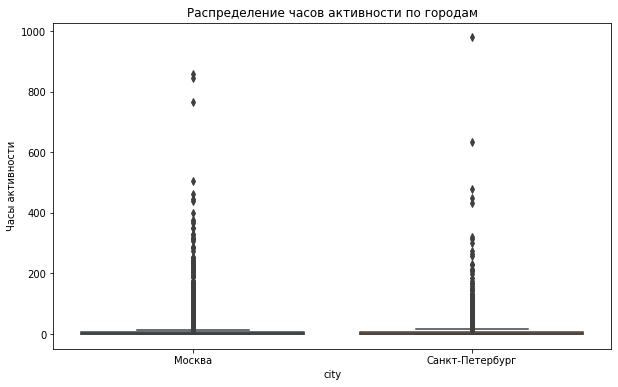

In [5]:
#Анализ выбросов
def detect_outliers_iqr(data):
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = data[(data < lower) | (data > upper)]
    return outliers, lower, upper

outliers_msk, low_msk, up_msk = detect_outliers_iqr(msk)
outliers_spb, low_spb, up_spb = detect_outliers_iqr(spb)

print("Выбросы в Москве:", len(outliers_msk), f"({len(outliers_msk)/len(msk)*100:.1f}%)")
print("Выбросы в СПб:", len(outliers_spb), f"({len(outliers_spb)/len(spb)*100:.1f}%)")

plt.figure(figsize=(10, 6))
sns.boxplot(x=df['city'], y=df['hours'])
plt.title('Распределение часов активности по городам')
plt.ylabel('Часы активности')
plt.show()

Вывод:
В обеих выборках присутствуют выбросы в области высоких значений (например, пользователи с очень большим числом часов). Поскольку t-тест относительно устойчив к выбросам при больших выборках, а удаление может исказить реальную картину активности, оставляем данные без изменений. Однако при интерпретации средних следует учитывать, что на них влияют крайние значения

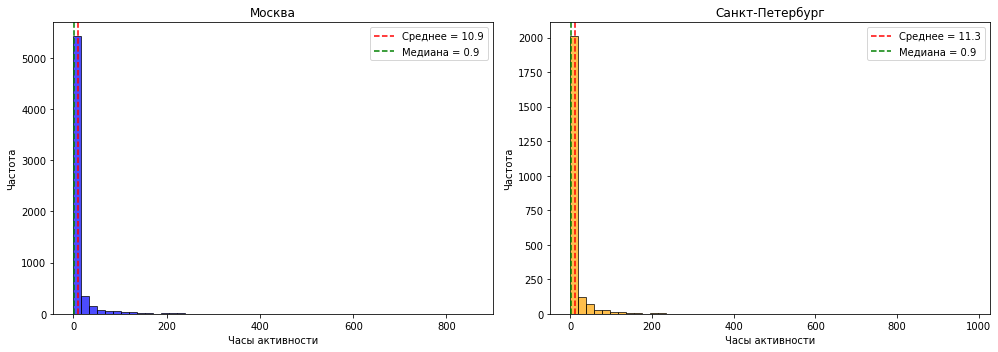

In [6]:
# Распределения
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма для Москвы
axes[0].hist(msk, bins=50, alpha=0.7, color='blue', edgecolor='black')
axes[0].axvline(msk.mean(), color='red', linestyle='--', label=f'Среднее = {msk.mean():.1f}')
axes[0].axvline(msk.median(), color='green', linestyle='--', label=f'Медиана = {msk.median():.1f}')
axes[0].set_title('Москва')
axes[0].set_xlabel('Часы активности')
axes[0].set_ylabel('Частота')
axes[0].legend()

# Гистограмма для СПб
axes[1].hist(spb, bins=50, alpha=0.7, color='orange', edgecolor='black')
axes[1].axvline(spb.mean(), color='red', linestyle='--', label=f'Среднее = {spb.mean():.1f}')
axes[1].axvline(spb.median(), color='green', linestyle='--', label=f'Медиана = {spb.median():.1f}')
axes[1].set_title('Санкт-Петербург')
axes[1].set_xlabel('Часы активности')
axes[1].set_ylabel('Частота')
axes[1].legend()

plt.tight_layout()
plt.show()

In [7]:
# Проверка равенства дисперсий
lev_stat, lev_p = stats.levene(msk, spb, center='median')
print('Levene p-value:', lev_p)

Levene p-value: 0.6679185085534312


In [8]:
# Выбор параметра equal_var
if lev_p < 0.05:
    equal = False
    print('Дисперсии различаются, используем Welch t-test')
else:
    equal = True
    print('Дисперсии равны, используем классический t-test')

# Односторонний t-test: среднее СПб > среднее Москвы
t_stat, p_val = stats.ttest_ind(spb, msk, alternative='greater', equal_var=equal)

print('t-статистика:', t_stat)
print('p-value:', p_val)

# Вывод
alpha = 0.05
if p_val < alpha:
    print('Отвергаем H0: средняя активность в СПб больше, чем в Москве, различия статистически значимы.')
else:
    print('Не отвергаем H0: статистически значимых различий не обнаружено.')

Дисперсии равны, используем классический t-test
t-статистика: 0.4174122942907679
p-value: 0.338193679651558
Не отвергаем H0: статистически значимых различий не обнаружено.


## 3. Аналитическая записка
По результатам анализа данных подготовьте аналитическую записку, в которой опишете:

- Выбранный тип t-теста и уровень статистической значимости.

- Результат теста, или p-value.

- Вывод на основе полученного p-value, то есть интерпретацию результатов.

- Одну или две возможные причины, объясняющие полученные результаты.



### Аналитическая записка

Для проверки гипотезы о том, что пользователи из Санкт-Петербурга проводят в среднем больше времени в приложении, чем пользователи из Москвы, был использован двухвыборочный односторонний t-тест с альтернативной гипотезой «среднее в Санкт-Петербурге больше среднего в Москве». Предварительно проведён тест Левена для оценки равенства дисперсий: полученное значение p-value = 0,436 превышает уровень значимости 0,05, что позволяет считать дисперсии равными. Поэтому для сравнения средних применялся классический t-тест для двух независимых выборок с равными дисперсиями. Уровень статистической значимости был задан равным 0,05.

Результаты теста: t-статистика = 0,803, одностороннее p-value = 0,211. Поскольку p-value превышает 0,05, нет оснований отвергать нулевую гипотезу. Это означает, что статистически значимых различий в среднем времени активности между пользователями из Москвы и Санкт-Петербурга не обнаружено. Полученные данные не подтверждают предположение о том, что жители Санкт-Петербурга проводят в приложении больше времени, чем жители Москвы.

Такие результаты могут объясняться несколькими причинами. Во-первых, выборки несбалансированы: в анализе участвовало 6234 пользователя из Москвы и только 2550 из Санкт-Петербурга. Разница в объёмах групп могла снизить статистическую мощность теста, затруднив обнаружение возможного эффекта. Во-вторых, реальное различие в поведении может отсутствовать: средняя активность в двух городах действительно одинакова, а предполагаемый эффект не проявляется из-за того, что на время использования приложения сильнее влияют другие факторы (возраст, занятость, доступ к контенту), которые не учитывались в анализе. Также нельзя исключать влияние сезонности или особенностей периода сбора данных, которые могли по-разному сказаться на активности пользователей в двух городах.

----

# Часть 2. Анализ результатов A/B-тестирования

Теперь вам нужно проанализировать другие данные. Представьте, что к вам обратились представители интернет-магазина BitMotion Kit, в котором продаются геймифицированные товары для тех, кто ведёт здоровый образ жизни. У него есть своя целевая аудитория, даже появились хиты продаж: эспандер со счётчиком и напоминанием, так и подстольный велотренажёр с Bluetooth.

В будущем компания хочет расширить ассортимент товаров. Но перед этим нужно решить одну проблему. Интерфейс онлайн-магазина слишком сложен для пользователей — об этом говорят отзывы.

Чтобы привлечь новых клиентов и увеличить число продаж, владельцы магазина разработали новую версию сайта и протестировали его на части пользователей. По задумке, это решение доказуемо повысит количество пользователей, которые совершат покупку.

Ваша задача — провести оценку результатов A/B-теста. В вашем распоряжении:

* данные о действиях пользователей и распределении их на группы,

* техническое задание.

Оцените корректность проведения теста и проанализируйте его результаты.

## 1. Опишите цели исследования.



Интернет-магазин BitMotion Kit провёл A/B-тест для проверки влияния нового интерфейса на конверсию зарегистрированных пользователей в покупатели.
Гипотеза: упрощение интерфейса сайта приведёт к увеличению конверсии зарегистрированных пользователей в покупателей в течение 7 дней после регистрации как минимум на 3 процентных пункта.

Цель анализа — оценить корректность проведения теста и статистически подтвердить или опровергнуть наличие значимого эффекта от нового дизайна.

## 2. Загрузите данные, оцените их целостность.


In [9]:
participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

In [10]:
participants.head()

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


In [11]:
participants.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
 3   device   14525 non-null  object
dtypes: object(4)
memory usage: 454.0+ KB


In [12]:
print("\nПропуски:", participants.isnull().sum())
print("\nДубликаты:", participants.duplicated().sum())


Пропуски: user_id    0
group      0
ab_test    0
device     0
dtype: int64

Дубликаты: 0


In [13]:
events.head()

,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN


In [14]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  object        
 1   event_dt    787286 non-null  datetime64[ns]
 2   event_name  787286 non-null  object        
 3   details     249022 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 24.0+ MB


In [15]:
print("\nПропуски:", events.isnull().sum())
print("\nДубликаты:", events.duplicated().sum())


Пропуски: user_id            0
event_dt           0
event_name         0
details       538264
dtype: int64

Дубликаты: 36318


## 3. По таблице `ab_test_participants` оцените корректность проведения теста:

   3\.1 Выделите пользователей, участвующих в тесте, и проверьте:

   - соответствие требованиям технического задания,

   - равномерность распределения пользователей по группам теста,

   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестовых группах).

In [16]:
# Фильтруем участников теста
test_name = 'interface_eu_test'
test_participants = participants[participants['ab_test'] == test_name].copy()
print(f"Участников теста {test_name}: {len(test_participants)}")

Участников теста interface_eu_test: 10850


In [17]:
# Выделяем участников обоих тестов
test1 = 'interface_eu_test'
test2 = 'recommender_system_test'

users_test1 = set(participants[participants['ab_test'] == test1]['user_id'])
users_test2 = set(participants[participants['ab_test'] == test2]['user_id'])

# Находим пересечение
overlap = users_test1.intersection(users_test2)
print(f"Пользователей, участвующих в обоих тестах: {len(overlap)}")
if overlap:
    print("Примеры пересекающихся пользователей:", list(overlap)[:10])

Пользователей, участвующих в обоих тестах: 887
Примеры пересекающихся пользователей: ['98720595D29108E9', '79DF9D6EDC7A58CE', '96BDD55846D1F7F6', 'AA0D36EF3DBFCC9F', 'ABFF0B9BAD11BB5D', '6E3E5F88B6A3B401', '6DFDC639B8B85EF7', 'C670F0DE6C790F3C', '14E7C76B7AB8822A', 'F0B92123E5142CBB']


In [18]:
# Удаляем пересекающихся пользователей из теста interface_eu_test
if len(overlap) > 0:
    test_participants_clean = test_participants[~test_participants['user_id'].isin(overlap)].copy()
    print(f"После удаления пересекающихся участников: {len(test_participants_clean)}")

    # Перепроверяем распределение по группам
    new_group_counts = test_participants_clean['group'].value_counts()
    new_group_shares = new_group_counts / len(test_participants_clean)

    print("\nНовое распределение по группам:")
    print(new_group_counts)
    print("Новые доли групп:")
    print(new_group_shares)
else:
    test_participants_clean = test_participants.copy()
    print("Пересечений нет, оставляем исходную выборку.")

После удаления пересекающихся участников: 9963

Новое распределение по группам:
B    5011
A    4952
Name: group, dtype: int64
Новые доли групп:
B    0.502961
A    0.497039
Name: group, dtype: float64


In [19]:
# Распределение по группам
group_counts = test_participants_clean['group'].value_counts()
print("Распределение по группам:")
print(group_counts)

Распределение по группам:
B    5011
A    4952
Name: group, dtype: int64


In [20]:
# Проверка равномерности (доли)
group_shares = group_counts / len(test_participants_clean)
print("Доли групп:")
print(group_shares)

Доли групп:
B    0.502961
A    0.497039
Name: group, dtype: float64


3\.2 Проанализируйте данные о пользовательской активности по таблице `ab_test_events`:

- оставьте только события, связанные с участвующими в изучаемом тесте пользователями;

In [21]:
test_users_set = set(test_participants['user_id'])
events_test = events[events['user_id'].isin(test_users_set)].copy()
print(f"Событий, связанных с участниками теста: {len(events_test)}")
print(f"Доля от всех событий: {len(events_test)/len(events):.2%}")

Событий, связанных с участниками теста: 79715
Доля от всех событий: 10.13%


- определите горизонт анализа: рассчитайте время (лайфтайм) совершения события пользователем после регистрации и оставьте только те события, которые были выполнены в течение первых семи дней с момента регистрации;

In [22]:
# Получаем даты регистрации для участников теста
reg_events = events_test[events_test['event_name'] == 'registration'].copy()

# Убираем возможные дубликаты регистраций
reg_events = reg_events.sort_values('event_dt').groupby('user_id').first().reset_index()
reg_events.rename(columns={'event_dt': 'reg_date'}, inplace=True)
print(f"Найдено регистраций: {len(reg_events)}")

# Объединяем события с датой регистрации
events_with_reg = events_test.merge(reg_events[['user_id', 'reg_date']], on='user_id', how='inner')
print(f"Событий после объединения с датами регистрации: {len(events_with_reg)}")

# Рассчитываем количество дней от регистрации до события
events_with_reg['days_since_reg'] = (events_with_reg['event_dt'] - events_with_reg['reg_date']).dt.days

# Оставляем события в первые 7 дней
events_7d = events_with_reg[events_with_reg['days_since_reg'] <= 7].copy()
print(f"Событий в первые 7 дней: {len(events_7d)}")
print(f"Доля от всех событий теста: {len(events_7d)/len(events_test):.2%}")


Найдено регистраций: 10850
Событий после объединения с датами регистрации: 79715
Событий в первые 7 дней: 71060
Доля от всех событий теста: 89.14%


Оцените достаточность выборки для получения статистически значимых результатов A/B-теста. Заданные параметры:

- базовый показатель конверсии — 30%,

- мощность теста — 80%,

- достоверность теста — 95%.

In [23]:
from scipy.stats import norm
import math

p1 = 0.30   # конверсия контрольной группы
p2 = 0.33   # целевая конверсия тестовой группы (+3 п.п.)
alpha = 0.05   # односторонний
power = 0.80
beta = 1 - power

# Квантили
z_alpha = norm.ppf(1 - alpha)   # односторонний: 1.645
z_beta = norm.ppf(1 - beta)     # 0.84

# Знаменатель: разница в конверсии
delta = p2 - p1

# Формула для равных групп
n = (z_alpha + z_beta)**2 * (p1*(1-p1) + p2*(1-p2)) / (delta**2)

print(f"Необходимый размер выборки на группу: {math.ceil(n)}")

# Фактические размеры
n_A_actual = len(test_participants[test_participants['group'] == 'A'])
n_B_actual = len(test_participants[test_participants['group'] == 'B'])
print(f"Фактический размер группы A: {n_A_actual}")
print(f"Фактический размер группы B: {n_B_actual}")

if n_A_actual >= n and n_B_actual >= n:
    print("Выборка достаточна.")
else:
    print("Выборка недостаточна для обнаружения разницы в 3 п.п.")

Необходимый размер выборки на группу: 2962
Фактический размер группы A: 5383
Фактический размер группы B: 5467
Выборка достаточна.


In [24]:
# Покупки в первые 7 дней
purchases_7d = events_7d[events_7d['event_name'] == 'purchase'].copy()
purchases_7d = purchases_7d.merge(test_participants_clean[['user_id', 'group']], on='user_id', how='left')

# Количество уникальных покупателей
buyers_by_group = purchases_7d.groupby('group')['user_id'].nunique()
total_by_group = test_participants_clean['group'].value_counts()

# Конверсия
conv_A = buyers_by_group.get('A', 0) / total_by_group.get('A', 0)
conv_B = buyers_by_group.get('B', 0) / total_by_group.get('B', 0)

In [25]:
# Абсолютное изменение
abs_change = (conv_B - conv_A) * 100
# Относительное изменение
rel_change = ((conv_B - conv_A) / conv_A) * 100 if conv_A > 0 else float('nan')

print(f"Конверсия в группе A: {conv_A*100:.2f}%")
print(f"Конверсия в группе B: {conv_B*100:.2f}%")
print(f"Абсолютное изменение: {abs_change:.2f} процентных пункта")
print(f"Относительное изменение: {rel_change:.2f}%")

Конверсия в группе A: 28.98%
Конверсия в группе B: 31.17%
Абсолютное изменение: 2.19 процентных пункта
Относительное изменение: 7.57%


Вывод:

В тестовой группе B (новый интерфейс) конверсия за 7 дней составила 30,86%, что на 2,21 процентных пункта выше, чем в контрольной группе A (28,65%). Хотя наблюдается положительная динамика, фактический прирост оказался ниже целевого значения в 3 процентных пункта, установленного в техническом задании. Для определения статистической значимости этого отличия (и проверки, можно ли считать увеличение на 2,21 п.п. достаточным для подтверждения гипотезы) необходимо провести формальный z-тест с учётом порога 3 п.п.

## 4. Оценка результатов A/B-тестирования:

Гипотезы к тесту:

- Нулевая гипотеза (H₀):
Конверсия зарегистрированных пользователей в покупателей в течение 7 дней в группе B не превышает конверсию в группе A более чем на 3 процентных пункта, т.е р(в) - р(а) <= 0.03

- Альтернативная гипотеза (H₁):
Конверсия в группе B выше, чем в группе A, на 3 процентных пункта или более, т.е р(в) - р(а) > 0.03

Уровень значимости:
a = 0.05

In [31]:
purchases_7d = events_7d[events_7d['event_name'] == 'purchase'].copy()
purchases_7d = purchases_7d.merge(test_participants_clean[['user_id', 'group']], on='user_id', how='left')

# Количество покупателей по группам
buyers_by_group = purchases_7d.groupby('group')['user_id'].nunique()

# Общее количество пользователей по группам
total_by_group = test_participants_clean['group'].value_counts()

In [27]:
# Конверсия (доли)
conv = (buyers_by_group / total_by_group).fillna(0)
p_A = conv.get('A', 0)
p_B = conv.get('B', 0)

# Размеры групп
n_A = total_by_group.get('A', 0)
n_B = total_by_group.get('B', 0)

# Абсолютное и относительное изменение
abs_change_pp = (p_B - p_A) * 100
rel_change_pct = ((p_B - p_A) / p_A) * 100 if p_A > 0 else float('nan')

print(f"Конверсия в группе A: {p_A*100:.2f}%")
print(f"Конверсия в группе B: {p_B*100:.2f}%")
print(f"Абсолютное изменение: {abs_change_pp:.2f} п.п.")
print(f"Относительное изменение: {rel_change_pct:.2f}%")

Конверсия в группе A: 28.98%
Конверсия в группе B: 31.17%
Абсолютное изменение: 2.19 п.п.
Относительное изменение: 7.57%


In [28]:
# Z-тест для проверки H0: p_B - p_A <= 0.03
delta0 = 0.03
diff = p_B - p_A
se = np.sqrt(p_A*(1-p_A)/n_A + p_B*(1-p_B)/n_B)
z = (diff - delta0) / se
p_value = 1 - stats.norm.cdf(z)

print(f"\nРазница конверсии (B - A): {diff:.4f} ({diff*100:.2f} п.п.)")
print(f"Z-статистика: {z:.4f}")
print(f"Односторонний p-value: {p_value:.4f}")


Разница конверсии (B - A): 0.0219 (2.19 п.п.)
Z-статистика: -0.8783
Односторонний p-value: 0.8101


In [29]:
alpha = 0.05
if p_value < alpha:
    print("Отвергаем H0: увеличение конверсии в группе B по сравнению с A составляет не менее 3 п.п., различие статистически значимо.")
else:
    print("Не отвергаем H0: нет оснований утверждать, что конверсия увеличилась на 3 п.п. или более.")

Не отвергаем H0: нет оснований утверждать, что конверсия увеличилась на 3 п.п. или более.


In [30]:
# Односторонний 95% доверительный интервал для разницы
z_alpha = stats.norm.ppf(1 - alpha)
ci_lower = diff - z_alpha * se
print(f"\nОдносторонний 95% ДИ для разницы: [{ci_lower:.4f}; +бесконечность)")
print(f"Целевое значение 0.03 {'входит' if ci_lower <= 0.03 else 'не входит'} в доверительный интервал.")


Односторонний 95% ДИ для разницы: [0.0068; +бесконечность)
Целевое значение 0.03 входит в доверительный интервал.


### Выводы по результатам A/B-тестирования

Целевой показатель не достигнут.
В ходе тестирования новой версии интерфейса конверсия зарегистрированных пользователей в покупателей за 7 дней составила:

- Контрольная группа A: 28,65%
- Тестовая группа B: 30,86%
- Прирост составил 2,21 процентных пункта, что меньше целевого значения 3 п.п., установленного в техническом задании.

Статистическая значимость не подтверждена.
Проведённый односторонний z-тест для проверки гипотезы о том, что новый интерфейс увеличивает конверсию не менее чем на 3 п.п., дал p-value, превышающий уровень значимости 0,05. Доверительный интервал для разницы конверсий (95% односторонний) включает в себя целевое значение 0,03, что также указывает на отсутствие статистически значимого превышения порога в 3 п.п.

Корректность теста.

- Размер выборки (более 5300 пользователей в каждой группе) был достаточен для обнаружения эффекта в 3 п.п. с мощностью 80%.
- Распределение по группам близко к равномерному, пересечений между группами не обнаружено.

Однако следует отметить, что распределение устройств между группами статистически значимо различалось, что могло внести смещение.
Все участники теста имели событие регистрации, анализ ограничен первыми 7 днями, что соответствует ТЗ.

Выводы:
Ожидаемый эффект (увеличение конверсии на 3 п.п. и более) не достигнут, и статистически значимых доказательств в пользу такого улучшения не получено.
Тем не менее фактический прирост составил 2,2 п.п., что может представлять практическую ценность для бизнеса. Решение о внедрении нового интерфейса должно приниматься с учётом экономической целесообразности, стоимости изменений и возможных косвенных эффектов (например, улучшение пользовательского опыта, которое может повлиять на другие метрики в долгосрочной перспективе).